# **Layer-wise feature trajectory analysis with DinoV3**
The goal of this notebook is to determine and visualize how the [CLS] tokens for different classes, such as 'Cat' and 'Dog', correlate and relate to one another after each attention block

## **1. Importing**

In [28]:
import torch
import numpy as np
import torchvision
from transformers import AutoImageProcessor, AutoModel
from torch.utils.data import DataLoader
import h5py
import random
import kagglehub
import os
from torchvision.datasets import ImageFolder
from torchvision import transforms
import requests
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt
import torch.nn.functional as F

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


### **1.1 Hugging Face**

In [4]:
from huggingface_hub import login
login()

In [5]:
model_name = "facebook/dinov3-vits16-pretrain-lvd1689m"
HDF5_FILE = "dino_features.h5"
print(f"Loading model: {model_name}")

model = AutoModel.from_pretrained(model_name).to(device).eval()

Loading model: facebook/dinov3-vits16-pretrain-lvd1689m


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/86.4M [00:00<?, ?B/s]

## **2. Data**

In [6]:
processor = AutoImageProcessor.from_pretrained(model_name)
transform = lambda img: processor(images=img, return_tensors="pt")['pixel_values'].squeeze()

preprocessor_config.json:   0%|          | 0.00/585 [00:00<?, ?B/s]

### **2.1 CIFAR-10/CIFAR-100**

In [7]:
dataset_cifar10 = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
loader_cifar10 = DataLoader(dataset_cifar10, batch_size=64, shuffle=False, num_workers=2)
print(f"Amount of CIFAR10 samples (OOD - CIFAR-10): {len(dataset_cifar10)}")

100%|██████████| 170M/170M [00:14<00:00, 12.1MB/s]


Amount of CIFAR10 samples (OOD - CIFAR-10): 10000


In [8]:
dataset_cifar100 = torchvision.datasets.CIFAR100(root='./data', train=False, download=True, transform=transform)
loader_cifar100 = DataLoader(dataset_cifar100, batch_size=64, shuffle=False, num_workers=2)
print(f"Amount of CIFAR100 samples (OOD - CIFAR-100): {len(dataset_cifar100)}")

100%|██████████| 169M/169M [00:13<00:00, 12.5MB/s]


Amount of CIFAR100 samples (OOD - CIFAR-100): 10000


### **2.2 Oxford-IIIT Pet**
Oxford-IIIT Pet provides hierarchical labels such as: Species: *Cat/Dog -> Breed: Persian/Beagle*.
This is crucial for our testing if the model seperates *species* in early layers and *breeds* in later layers

In [9]:
from torchvision.datasets import OxfordIIITPet

In [10]:
dataset_pets = OxfordIIITPet(root='./data', split='test', download=True, transform=transform)
loader_pets = DataLoader(dataset_pets, batch_size=64, shuffle=False, num_workers=2)

print(f"Amount of OxfordIIITPet samples: {len(dataset_pets)}")

100%|██████████| 792M/792M [00:35<00:00, 22.6MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 10.2MB/s]


Amount of OxfordIIITPet samples: 3669


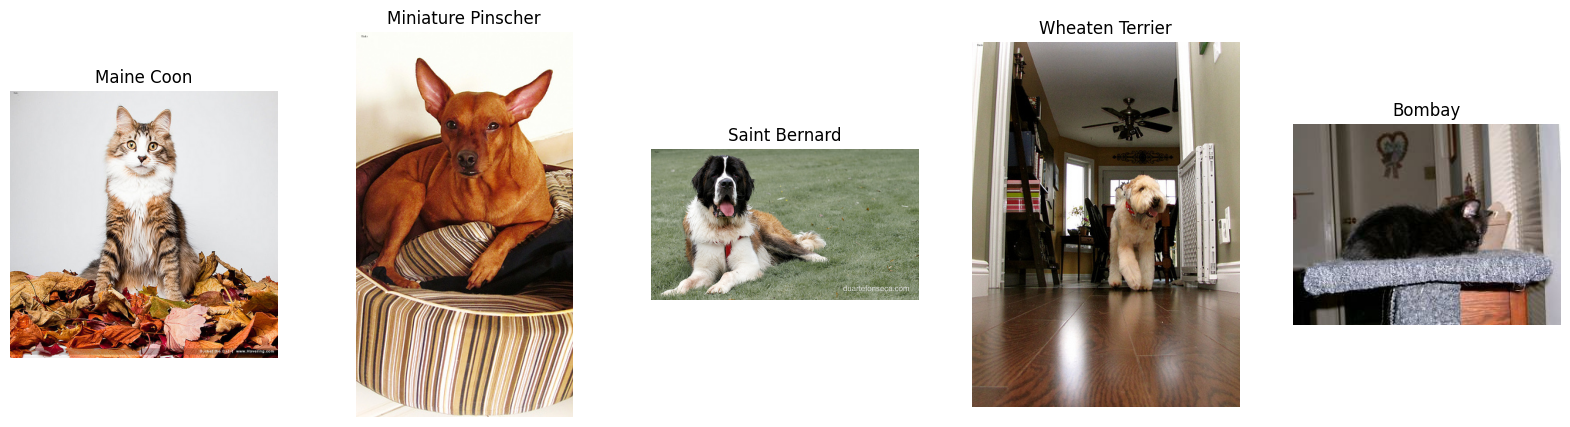

In [11]:
vis_dataset = OxfordIIITPet(root='./data', split='test', download=True, transform=None)

class_names = vis_dataset.classes

random_indices = random.sample(range(len(vis_dataset)), 5)
fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, idx in zip(axes, random_indices):
    img, target = vis_dataset[idx]

    predicted_name = class_names[target]

    ax.imshow(img)
    ax.set_title(predicted_name)
    ax.axis('off')

plt.show()

### **2.3 High Resolution images**
Since Oxford-IIIT Pet image dataset is in HD quality it might be enough to conduct our experiment. For our purposes we will try to import high-resolution images as well.

In [12]:
image_urls = {
    "cat_1": "https://upload.wikimedia.org/wikipedia/commons/thumb/b/b6/Felis_catus-cat_on_snow.jpg/640px-Felis_catus-cat_on_snow.jpg",
    "cat_2": "https://upload.wikimedia.org/wikipedia/commons/thumb/4/4d/Cat_November_2010-1a.jpg/1024px-Cat_November_2010-1a.jpg",
    "cat_3": "https://upload.wikimedia.org/wikipedia/commons/thumb/4/47/Scottish-Fold.jpg/640px-Scottish-Fold.jpg",
    "dog_1": "https://upload.wikimedia.org/wikipedia/commons/thumb/7/77/Shiba_Inu_red.jpg/640px-Shiba_Inu_red.jpg",
    "dog_2": "https://upload.wikimedia.org/wikipedia/commons/thumb/4/4b/Siberian-husky-1291343_1920.jpg/640px-Siberian-husky-1291343_1920.jpg",
    "dog_3": "https://upload.wikimedia.org/wikipedia/commons/thumb/c/c8/Pug_dog.JPG/640px-Pug_dog.JPG"
}

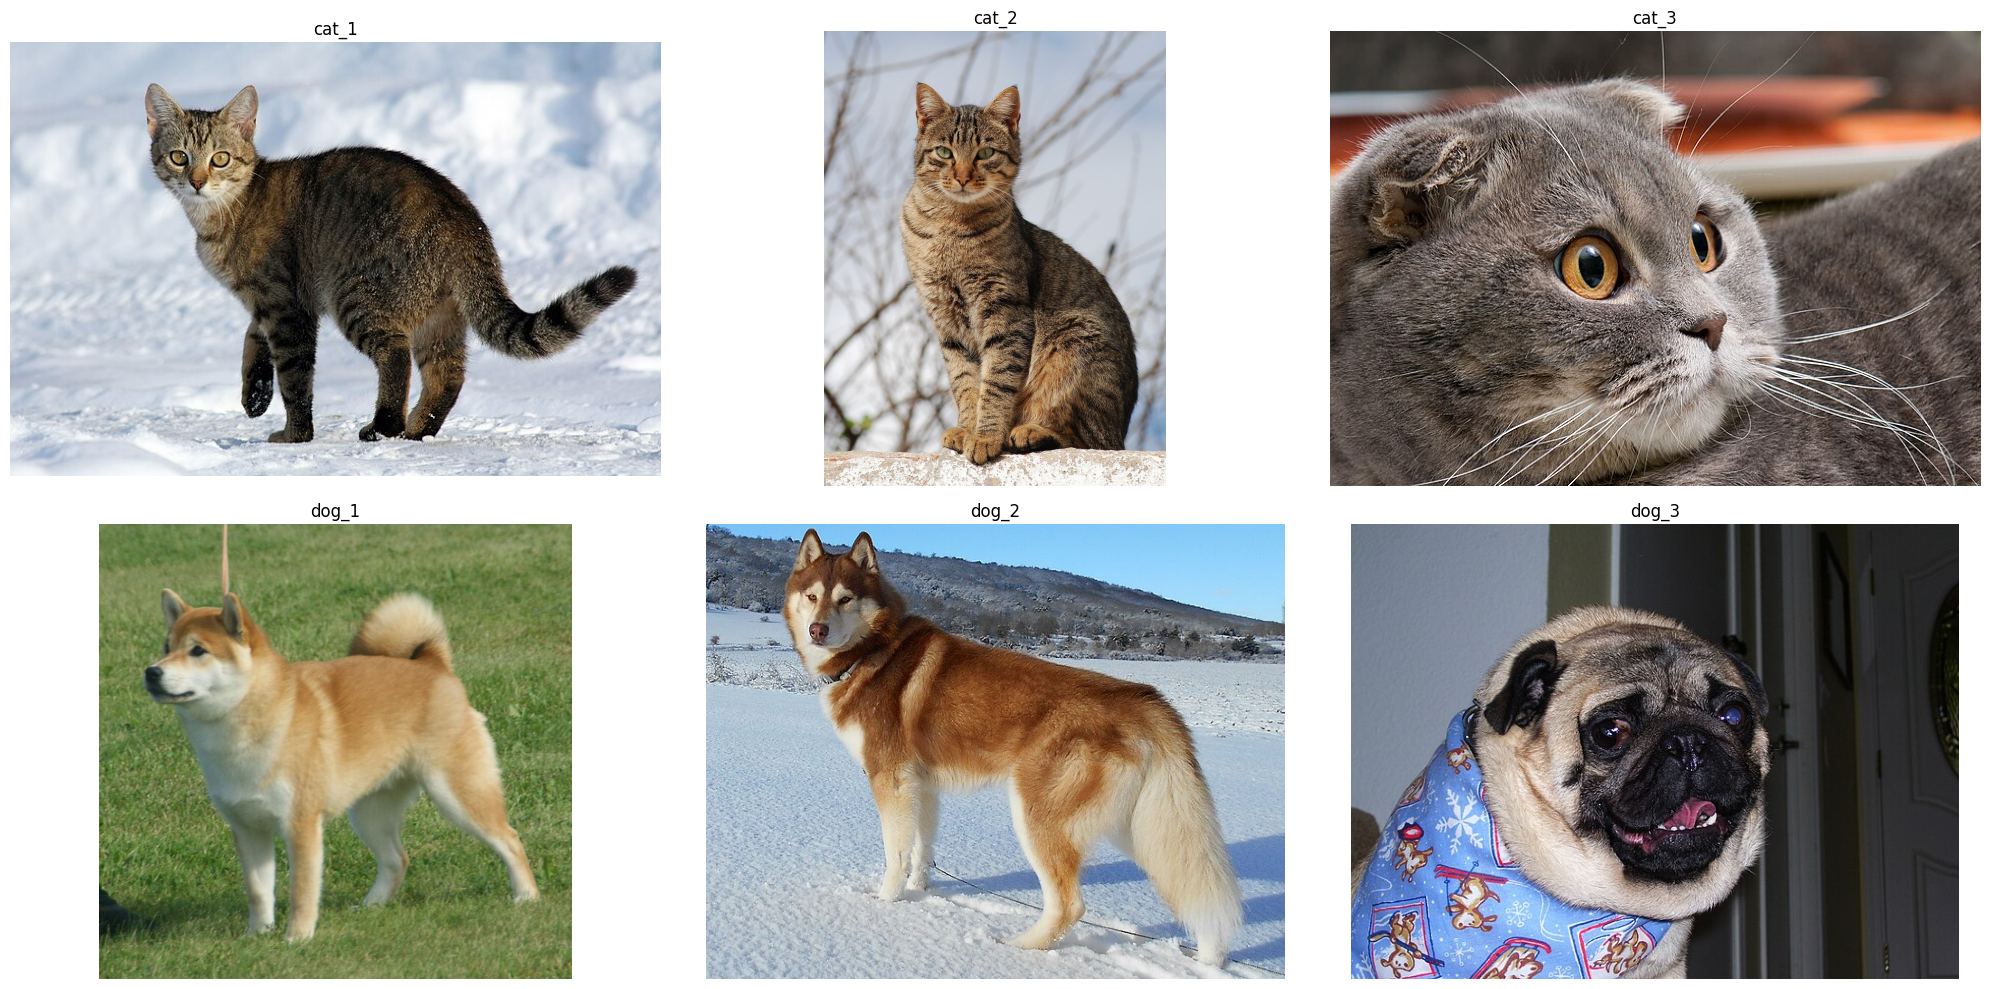

In [13]:
num_cols = len(image_urls) // 2
fig, axes = plt.subplots(2, num_cols, figsize=(20, 10))
axes = axes.flatten()

# Updated headers with Referer
headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36',
    'Referer': 'https://www.wikipedia.org/'
}

for ax, (name, url) in zip(axes, image_urls.items()):
    try:
        response = requests.get(url, headers=headers, timeout=10)
        response.raise_for_status()  # Check for HTTP errors (404, 403, etc.)

        img = Image.open(BytesIO(response.content))
        ax.imshow(img)
        ax.set_title(name)
        ax.axis('off')
    except Exception as e:
        print(f"Failed to load {name}: {e}")
        if 'response' in locals():
            print(f"Status Code: {response.status_code}")
            print(f"Response snippet: {response.text[:150]}...")
        ax.text(0.5, 0.5, f"Error loading\n{name}", ha='center', va='center')
        ax.axis('off')

plt.tight_layout()
plt.show()

## **3. DinoV3 Architecture**
At its core, DinoV3 is a **Vision Transformer (ViT)**. It is a massive stack of processing layers that takes an image, chops it into pieces, and learns how those pieces relate to each other.




### **3.1 Input patches**
Before the model does any thinking, it takes our image and cuts it into a grid of small squares called patches
*   **Patch Size**: 16x16 pixels
*   This turns a large picture into a sequence of small "tokens," similar to how a
language model processes a sentence word-by-word.


### **3.2 Layers**
The model is very deep. It consists of a stack of identical "building blocks" that process the information sequentially.
*   **Number of Layers**: There are **40 blocks** stacked on top of each other
*   **Embedding Dimension**: As the image data moves through these 40 layers, it is represented by a very wide vector of numbers. The "width" of this information highway is **4096 dimensions**.

### **3.3 Inside Each Layer**
*   **Attention block**: Each attention block in DinoV3 uses **32 attention heads**
*   **Multi-Layer Perceptron**: DinoV3 uses a modern, efficient version of an MLP called SwiGLU. The hidden dimension inside this MLP is massive—8192 —allowing it to store a vast amount of knowledge about visual concepts.


### **3.4 Special Features**
As a modern model DinoV3 includes few tricks.
*   **Register Token**: he model adds **4 extra "blank"** tokens to the input. Sometimes an image has "junk" data or background noise. These registers act like a trash bin, giving the model a place to store useless information so it doesn't clutter up the important features (like your Cat or Dog).
*   **Rotary Positional Embeddings (RoPE)**: Since the model chops the image into pieces, it needs to know where each piece goes (top-left, bottom-right, etc.). DinoV3 uses a system called axial RoPE to mathematically encode this location data, helping the model understand shapes and distances better



## **4. Acquiring activations**


### **4.1 Implementation**

In [14]:
activations = {}

In [15]:
def get_activation(name):
  """
  Gets an activation function for a specific layer in the model.

  :param name: The name of the layer to get the activation function for.
  """
  def hook(model, input, output):
    if isinstance(output, tuple):
      activations[name] = output[0].detach().cpu()
    else:
      activations[name] = output.detach().cpu()
  return hook

In [20]:
# Determine the correct attribute for the transformer blocks
if hasattr(model, "encoder") and hasattr(model.encoder, "layer"):
    # Standard Hugging Face ViT
    layers = model.encoder.layer
elif hasattr(model, "blocks"):
    # Common in timm and DINO implementations
    layers = model.blocks
elif hasattr(model, "layers"):
    # Generic fallback
    layers = model.layers
elif hasattr(model, "layer"):
    # Found in DINOv3ViTModel
    layers = model.layer
else:
    # If we can't find it, print the model to inspect structure
    print(model)
    raise AttributeError("Could not automatically locate the transformer blocks. See model structure above.")

for i, layer in enumerate(layers):
    layer_name = f"block_{i}"
    layer.register_forward_hook(get_activation(layer_name))

### **4.2 High resolution images**


In [21]:
batch_high_images = []
batch_high_labels = []

In [23]:
# Define headers to prevent 403 Forbidden errors from Wikimedia
headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36',
    'Referer': 'https://www.wikipedia.org/'
}

print("Downloading and transforming images...")
for name, url in image_urls.items():
  try:
    # Added headers here
    response = requests.get(url, headers=headers, timeout=10)
    response.raise_for_status()

    img = Image.open(BytesIO(response.content)).convert("RGB")

    img_tensor = transform(img)
    batch_high_images.append(img_tensor)
    batch_high_labels.append(name)

    print(f"Downloaded and transformed {name}")
  except Exception as e:
    print(f"Failed to download and transform {name}: {e}")

if batch_high_images:
    input_batch = torch.stack(batch_high_images).to(device)

    print(f"Running inference on batch of shape: {input_batch.shape}")
    with torch.no_grad():
        _ = model(pixel_values=input_batch)

    animal_trajectories = {name: {} for name in batch_high_labels}
else:
    print("No images were successfully loaded. Please check the URLs or your connection.")

Downloaded and transformed cat_1
Downloaded and transformed cat_2
Downloaded and transformed cat_3
Downloaded and transformed dog_1
Downloaded and transformed dog_2
Downloaded and transformed dog_3
Running inference on batch of shape: torch.Size([6, 3, 224, 224])


In [30]:
spatial_activations = {}

In [25]:
for layer_name, layer_tensor in activations.items():
    for batch_idx, animal_name in enumerate(batch_high_labels):

      cls_vector = layer_tensor[batch_idx, 0, :]
      animal_trajectories[animal_name][layer_name] = cls_vector

print("\nExtraction complete.")

last_layer = list(activations.keys())[-1]

print(f"Example: 'cat_1' at '{last_layer}' has vector shape: {animal_trajectories['cat_1'][last_layer].shape}")


Extraction complete.
Example: 'cat_1' at 'block_11' has vector shape: torch.Size([384])


In [26]:
# Inspect the structure of the dictionary
print(f"Main keys (Animals): {list(animal_trajectories.keys())}")

# Look at the first animal's layers
first_animal = list(animal_trajectories.keys())[0]
print(f"\nLayers for '{first_animal}': {list(animal_trajectories[first_animal].keys())[:5]} ... (showing first 5)")

# Look at the actual data
layer_0 = animal_trajectories[first_animal]['block_0']
print(f"\nVector at block_0 for '{first_animal}':\n Shape: {layer_0.shape}\n First 5 values: {layer_0[:5]}")

Main keys (Animals): ['cat_1', 'cat_2', 'cat_3', 'dog_1', 'dog_2', 'dog_3']

Layers for 'cat_1': ['block_0', 'block_1', 'block_2', 'block_3', 'block_4'] ... (showing first 5)

Vector at block_0 for 'cat_1':
 Shape: torch.Size([384])
 First 5 values: tensor([-0.0168, -0.0604, -0.0562,  0.0745,  0.0684])


## **Visualisation**

### **Cosine similiarity**
**Cosine similarity** is a metric used to measure how similar two vectors are irrespective of their size (magnitude). Mathematically, it measures the cosine of the angle between two vectors projected in a multi-dimensional space.

**The Geometric Intuition**
*   **Direction**: Represents the semantic content (e.g., "Feline characteristics")
*   **Magnitude (Length)**: Represents the strength or confidence of that feature (or sometimes image brightness/contrast).

Cosine similarity ignores the length and focuses strictly on the direction.

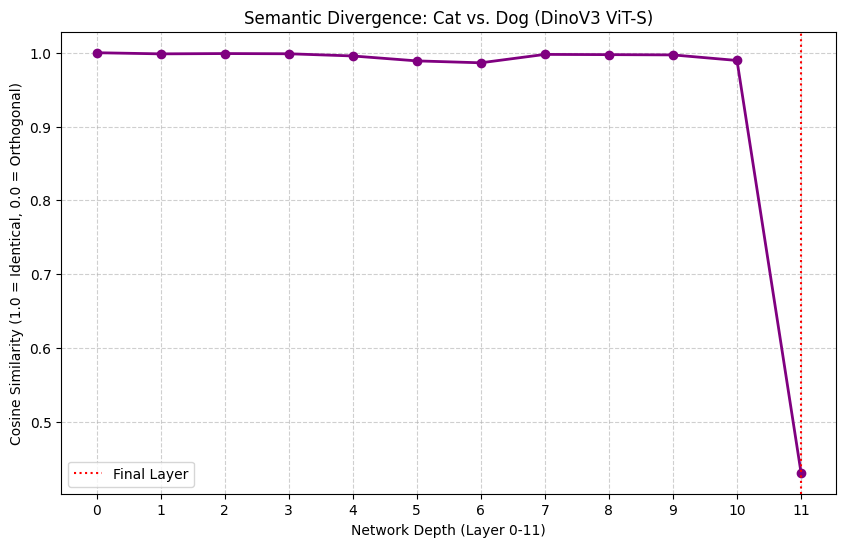

In [29]:
layers = [f"block_{i}" for i in range(12)]
cats = ["cat_1", "cat_2", "cat_3"]
dogs = ["dog_1", "dog_2", "dog_3"]

similarities = []

for layer in layers:
    cat_vecs = torch.stack([animal_trajectories[c][layer] for c in cats])
    dog_vecs = torch.stack([animal_trajectories[d][layer] for d in dogs])

    cat_centroid = torch.mean(cat_vecs, dim=0).unsqueeze(0)
    dog_centroid = torch.mean(dog_vecs, dim=0).unsqueeze(0)

    sim = F.cosine_similarity(cat_centroid, dog_centroid).item()
    similarities.append(sim)

plt.figure(figsize=(10, 6))
plt.plot(range(12), similarities, marker='o', linewidth=2, color='purple')
plt.title("Semantic Divergence: Cat vs. Dog (DinoV3 ViT-S)")
plt.xlabel("Network Depth (Layer 0-11)")
plt.ylabel("Cosine Similarity (1.0 = Identical, 0.0 = Orthogonal)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(range(12))
plt.axvline(x=11, color='red', linestyle=':', label='Final Layer')
plt.legend()
plt.show()

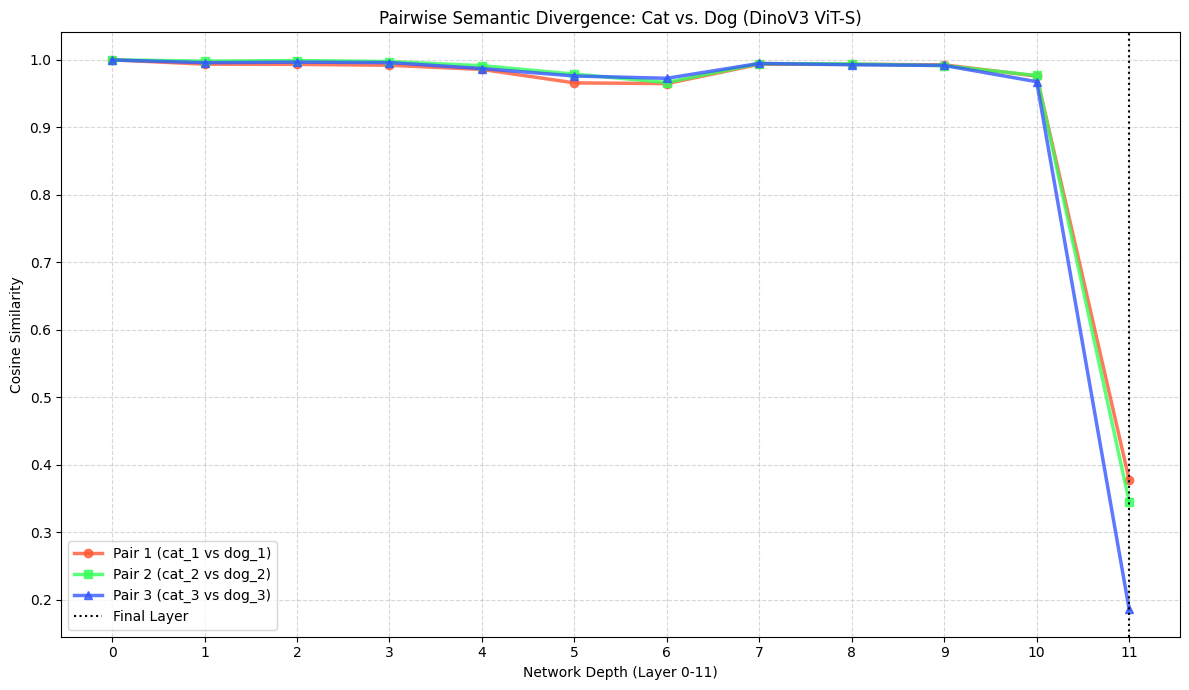

In [33]:
layers = [f"block_{i}" for i in range(12)]
cats = ["cat_1", "cat_2", "cat_3"]
dogs = ["dog_1", "dog_2", "dog_3"]

pairwise_trajectories = {f"Pair {i+1} ({c} vs {d})": [] for i, (c, d) in enumerate(zip(cats, dogs))}

for layer in layers:
    for i, (cat_name, dog_name) in enumerate(zip(cats, dogs)):
        cat_vec = animal_trajectories[cat_name][layer].unsqueeze(0)
        dog_vec = animal_trajectories[dog_name][layer].unsqueeze(0)

        sim = F.cosine_similarity(cat_vec, dog_vec).item()

        key = f"Pair {i+1} ({cat_name} vs {dog_name})"
        pairwise_trajectories[key].append(sim)

plt.figure(figsize=(12, 7))

colors = ['#FF5733', '#33FF57', '#3357FF']
markers = ['o', 's', '^']

for idx, (label, sims) in enumerate(pairwise_trajectories.items()):
    plt.plot(range(12), sims,
             marker=markers[idx % len(markers)],
             linewidth=2.5,
             color=colors[idx % len(colors)],
             label=label,
             alpha=0.8)

plt.title("Pairwise Semantic Divergence: Cat vs. Dog (DinoV3 ViT-S)")
plt.xlabel("Network Depth (Layer 0-11)")
plt.ylabel("Cosine Similarity")
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(range(12))
plt.axvline(x=11, color='black', linestyle=':', label='Final Layer')
plt.legend()
plt.tight_layout()
plt.show()

## **Pearson Correlation**
The Pearson correlation coefficient is a statistical metric that measures the strength and direction of the linear relationship between two continuous variables (or vectors).

Unlike Cosine Similarity, which measures the angle from the origin, Pearson Correlation centers the data by subtracting the mean of each vector before measuring alignment. This means it focuses purely on the pattern of variation (the shape of peaks and valleys) rather than the magnitude or absolute position of the values.

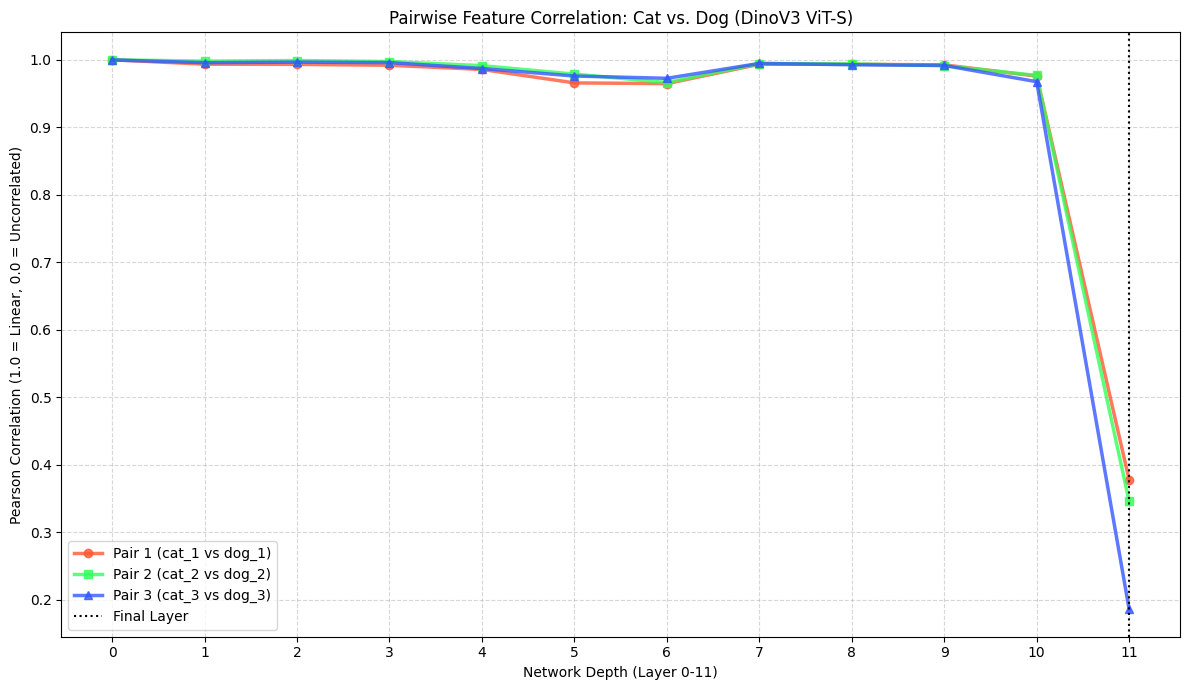

In [34]:
def pearson_correlation(v1, v2):
    """
    Calculates Pearson correlation between two 1D tensors.
    Formula: Covariance(v1, v2) / (StdDev(v1) * StdDev(v2))
    """
    # Center the vectors (subtract mean) to look at the pattern, not magnitude
    v1_centered = v1 - v1.mean()
    v2_centered = v2 - v2.mean()

    # Compute cosine similarity of centered vectors (which is mathematically Pearson)
    return torch.nn.functional.cosine_similarity(
        v1_centered.unsqueeze(0),
        v2_centered.unsqueeze(0)
    ).item()

# 2. Setup
layers = [f"block_{i}" for i in range(12)]
cats = ["cat_1", "cat_2", "cat_3"]
dogs = ["dog_1", "dog_2", "dog_3"]

correlation_trajectories = {f"Pair {i+1} ({c} vs {d})": [] for i, (c, d) in enumerate(zip(cats, dogs))}

# 3. Calculate Correlation per Pair per Layer
for layer in layers:
    for i, (cat_name, dog_name) in enumerate(zip(cats, dogs)):
        # Retrieve specific vectors (Shape: 384)
        cat_vec = animal_trajectories[cat_name][layer]
        dog_vec = animal_trajectories[dog_name][layer]

        # Calculate Pearson Correlation
        corr = pearson_correlation(cat_vec, dog_vec)

        # Store
        key = f"Pair {i+1} ({cat_name} vs {dog_name})"
        correlation_trajectories[key].append(corr)

# 4. Plotting
plt.figure(figsize=(12, 7))

colors = ['#FF5733', '#33FF57', '#3357FF']
markers = ['o', 's', '^']

for idx, (label, corrs) in enumerate(correlation_trajectories.items()):
    plt.plot(range(12), corrs,
             marker=markers[idx % len(markers)],
             linewidth=2.5,
             color=colors[idx % len(colors)],
             label=label,
             alpha=0.8)

plt.title("Pairwise Feature Correlation: Cat vs. Dog (DinoV3 ViT-S)")
plt.xlabel("Network Depth (Layer 0-11)")
plt.ylabel("Pearson Correlation (1.0 = Linear, 0.0 = Uncorrelated)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(range(12))
plt.axvline(x=11, color='black', linestyle=':', label='Final Layer')
plt.legend()
plt.tight_layout()
plt.show()